# Аудит признаков отбора Top‑3/5/10

## Краткий вывод
Историческая проверка исходных решений, с разделением прогнозирования голов и доходности точной линии. Числа ниже рассчитаны из сохранённых исходников; это наблюдательный анализ, не доказательство причинности и не будущий независимый тест.

## Контекст и метод
Один исходный вход на матч. Первый выбор без цены не заменяется поздним. В строгой проверке обучающие исходы должны быть записаны до начала проверяемого дня. Сопоставление учитывает минуту, счёт, линию, коэффициент, версию, страну и доступные ранее лиги. Пропуски имеют отдельные признаки. Источники: родительский results.json и original-entries.json.gz; SHA256 входа записан в league-adjusted-results.json.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
scope=json.loads(Path('quality-scope.json').read_text())
validation=json.loads(Path('league-adjusted-results.json').read_text())
models=validation['strict_league_adjusted_walk_forward']['models']
print('Период:',scope['quality']['earliest_entry_utc'],'-',scope['quality']['latest_entry_utc'])
print('Исходных уникальных матчей:',scope['quality']['deduplicated_original_events'])
print('Зрелая выборка с точной ценой:',scope['baseline_exact_mature']['n'])

Период: 2026-10-13T10:39:00+00:00 - 2026-10-24T17:16:50.791157+00:00
Исходных уникальных матчей: 1413
Зрелая выборка с точной ценой: 1185


## Результаты
### Признаки сверх линии, цены и контекста
Положительное изменение означает более точный прогноз оставшихся голов. Интервалы получены повторной выборкой целых дней; они описательные.

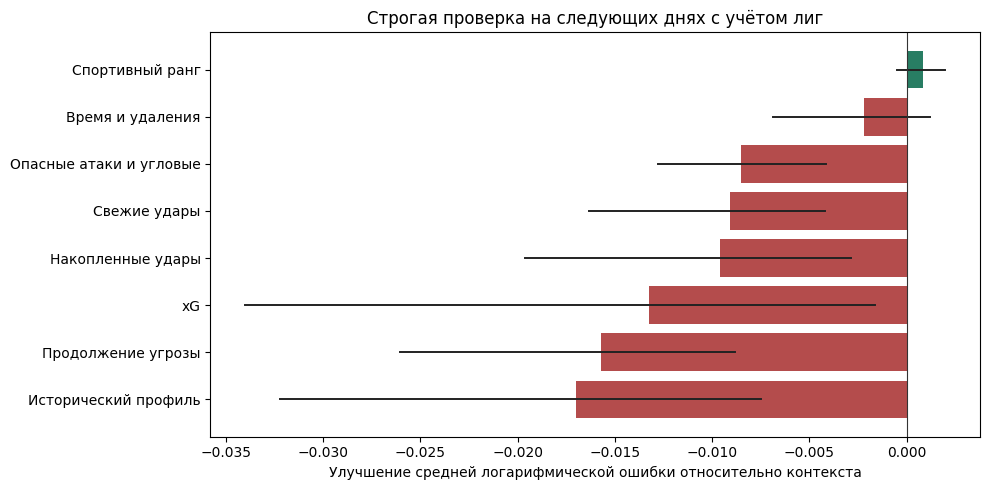

Спортивный ранг N= 873 Δ= 0.0009 q= 0.995
Время и удаления N= 873 Δ= -0.0022 q= 0.995
Опасные атаки и угловые N= 873 Δ= -0.0085 q= 0.995
Свежие удары N= 873 Δ= -0.0091 q= 0.995
Накопленные удары N= 873 Δ= -0.0096 q= 0.995
xG N= 873 Δ= -0.0132 q= 0.995
Продолжение угрозы N= 873 Δ= -0.0157 q= 0.995
Исторический профиль N= 873 Δ= -0.017 q= 0.995


In [2]:
labels={'cumulative_shots':'Накопленные удары','fresh_shots':'Свежие удары','continuation':'Продолжение угрозы','territorial':'Опасные атаки и угловые','xg':'xG','historical_profile':'Исторический профиль','sports_rank':'Спортивный ранг','clock_and_cards':'Время и удаления'}
keys=[k for k in labels if models[k].get('n')]
keys.sort(key=lambda k:models[k]['nll_improvement_over_context'])
y=np.arange(len(keys));vals=np.array([models[k]['nll_improvement_over_context'] for k in keys])
fig,ax=plt.subplots(figsize=(10,5))
ax.barh(y,vals,color=['#287d63' if v>0 else '#b44c4c' for v in vals])
for i,k in enumerate(keys):
 lo,hi=models[k]['day_bootstrap_improvement_ci95'];ax.plot([lo,hi],[i,i],color='#222222',linewidth=1.4)
ax.set_yticks(y,[labels[k] for k in keys]);ax.axvline(0,color='#333333',linewidth=.8);ax.set_xlabel('Улучшение средней логарифмической ошибки относительно контекста')
ax.set_title('Строгая проверка на следующих днях с учётом лиг');fig.tight_layout();fig.savefig('family-validation.png',dpi=150);plt.show()
for k in reversed(keys):
 m=models[k];print(labels[k], 'N=',m['n'],'Δ=',round(m['nll_improvement_over_context'],4),'q=',round(m.get('day_level_q_bh',1),3))

### Рост оценки качества и фактическая доходность
Фиксированные диапазоны прогноза прямой доходности полной модели. Это результаты только на последующих днях, без подбора порогов по проверяемому дню.

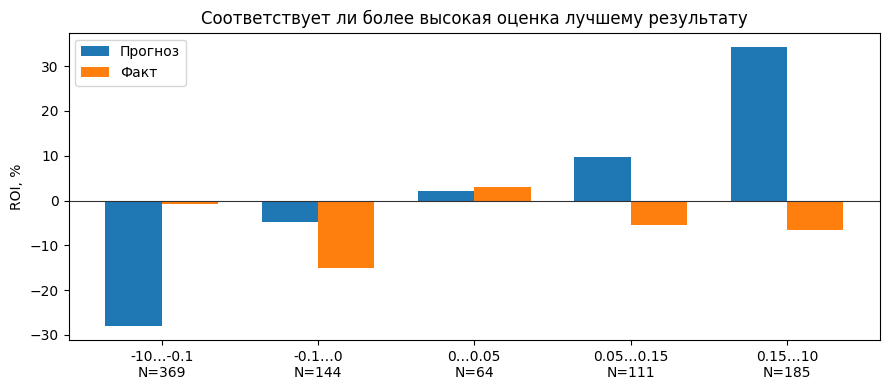

In [3]:
bins=models['all_sports'].get('direct_expected_return_bins',[])
bins=[b for b in bins if b['n']]
fig,ax=plt.subplots(figsize=(9,4));x=np.arange(len(bins))
ax.bar(x-.18,[100*b['predicted_roi'] for b in bins],width=.36,label='Прогноз')
ax.bar(x+.18,[100*b['actual_roi'] for b in bins],width=.36,label='Факт')
ax.set_xticks(x,[str(b['lower'])+'…'+str(b['upper'])+'\nN='+str(b['n']) for b in bins]);ax.axhline(0,color='#333333',linewidth=.8);ax.set_ylabel('ROI, %');ax.set_title('Соответствует ли более высокая оценка лучшему результату');ax.legend();fig.tight_layout();fig.savefig('return-calibration.png',dpi=150);plt.show()

## Ограничения и выводы
Архив начинается 13 октября. Результаты разных лимитов и версий относятся к разным календарным матчам. Часть рангов - порядок показа, они не смешиваются со спортивными рангами. Устаревшие, неизвестные и незавершённые исходы не становятся проигрышами. Поправка на множественные проверки приближённая. Полная реконструкция неполученных альтернатив и незафиксированных человеческих решений невозможна. Производственные правила и 20 независимых карманов этим аудитом не меняются.